# Case study: forecasting monthly Airbnb demand in Berlin

*Session 12, worked example of both blocks. Author: course team, licence CC-BY-4.0. Data: Inside Airbnb, Berlin, snapshot of 26 June 2026 (CC BY 4.0); daily Berlin weather from Open-Meteo (CC BY 4.0).*

**Question.** How many Airbnb stays will there be in Berlin per month over the next twelve months, and how certain is that forecast? We measure stays by their proxy, the number of guest reviews per month. A host, a cleaning company or a city office could use such a forecast to plan prices, staff or monitoring.

- **Part 1 (block 1):** build the monthly series from `reviews_monthly.parquet`, check its quality, describe it and compute the baselines.
- **Part 2 (block 1):** fit exponential smoothing with a prediction interval, decide how to treat the pandemic, and compare with the baselines and the airline ARIMA model.
- **Part 3 (block 2):** add a lag-feature model, backtest all models from six rolling origins, test whether the Berlin weather adds anything, and recommend one with its prediction interval.
- **Part 4 (optional):** the same comparison for the twelve districts: many smaller series instead of one.

Theory: [lecture of block 1](01-lecture-time-series-baselines-and-exponential-smoothing.ipynb), [lecture of block 2](04-lecture-lag-features-and-backtesting.ipynb). Prepare the data once with `uv run python case-study/prepare_airbnb.py`.

*Ethics:* the data are scraped from public listing pages. Work with aggregates; do not single out hosts.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")     # statsmodels convergence notes
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 12)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").exists())
DATA = ROOT / "case-study" / "data" / "airbnb"

# Part 1: the series and its baselines

## 1.1 From the review table to a monthly series

`reviews_monthly` has one row per listing and month with at least one review.

In [2]:
reviews = pd.read_parquet(DATA / "reviews_monthly.parquet")
print(reviews.head(3).to_string())
full = reviews.groupby("month")["n_reviews"].sum()
print("first and last months:", full.index.min().date(), full.index.max().date())
full.groupby(full.index.year).sum().rename("reviews per year").to_frame().T

   listing_id      month  n_reviews
0        3176 2009-06-01          1
1        3176 2010-11-01          2
2        3176 2010-12-01          1
first and last months: 2009-06-01 2026-07-01


month,2009,2010,2011,2012,2013,2014,...,2021,2022,2023,2024,2025,2026
reviews per year,1,46,181,710,1963,4930,...,35447,70471,87051,110776,130357,63445


**Questions.** (a) Look at the last two months (`full.tail()`). The snapshot was scraped between 26 June and 3 July 2026: why must June and July 2026 be dropped? (b) The table only contains listings that still existed in June 2026. What does that do to the counts of 2016 compared with 2025?

125 months; {Timestamp('2019-07-01 00:00:00'): 4865, Timestamp('2020-04-01 00:00:00'): 285, Timestamp('2025-07-01 00:00:00'): 13132}


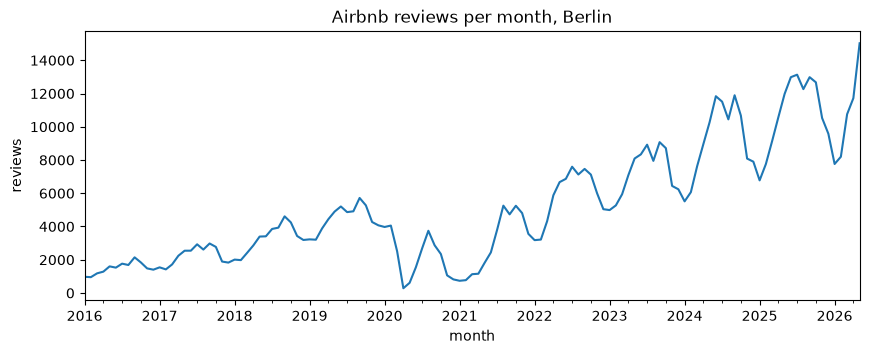

In [3]:
y = full["2016":"2026-05"].rename("reviews")
y.index.freq = "MS"
log_y = np.log(y)
ax = y.plot(figsize=(10, 3.5), title="Airbnb reviews per month, Berlin")
ax.set_ylabel("reviews")
print(len(y), "months;", y.loc[["2019-07-01", "2020-04-01", "2025-07-01"]].to_dict())

## 1.2 Trend, seasonality, autocorrelation

month,1,2,3,4,5,6,7,8,9,10,11,12
seasonal factor 2022-2025,0.71,0.74,0.89,1.03,1.18,1.24,1.24,1.14,1.23,1.14,0.88,0.81


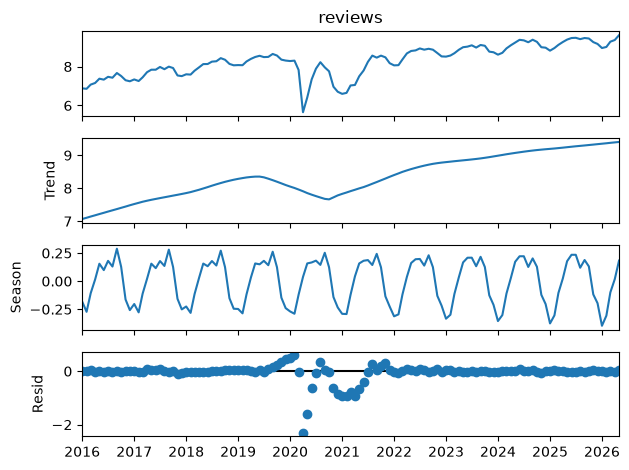

In [4]:
stl = STL(log_y, period=12, seasonal=13, robust=True).fit()
stl.plot()
plt.tight_layout()
recent = stl.seasonal["2022":"2025"]
np.exp(recent).groupby(recent.index.month).mean().round(2).rename("seasonal factor 2022-2025").to_frame().T

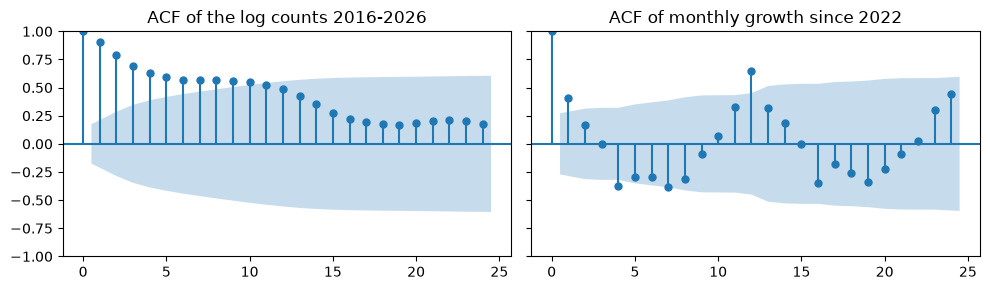

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
plot_acf(log_y, lags=24, ax=a1, title="ACF of the log counts 2016-2026")
plot_acf(log_y["2022":].diff().dropna(), lags=24, ax=a2, title="ACF of monthly growth since 2022")
plt.tight_layout()

**Question.** Which months are high, which low? How large is the pandemic dip in the remainder? Why is the left ACF high at every lag?

## 1.3 Baselines on the hold-out year (June 2025 to May 2026)

,MAE,MASE
naive,1710.42,1.03
seasonal naive,1586.17,0.96
moving average (3),1935.47,1.17
seasonal naive x growth,1037.57,0.63


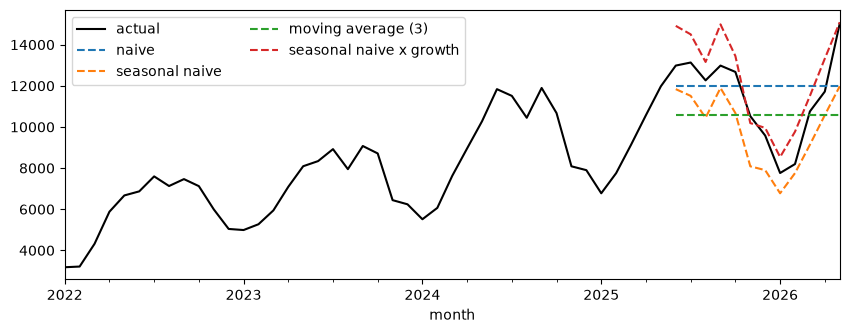

In [6]:
train, test = y[:"2025-05"], y["2025-06":]
H = len(test)
covid = pd.Series((y.index >= "2020-03-01") & (y.index <= "2021-12-01"), index=y.index)


def mae(actual, forecast):
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(forecast))))


def mase(actual, forecast, y_tr, m=12):
    history = y_tr["2022":].to_numpy()                 # scale without the pandemic years
    return mae(actual, forecast) / np.mean(np.abs(history[m:] - history[:-m]))


def baselines(y_tr, index):
    last_year = y_tr.iloc[-12:].to_numpy()[:len(index)]
    return {
        "naive": pd.Series(y_tr.iloc[-1], index=index),
        "seasonal naive": pd.Series(last_year, index=index),
        "moving average (3)": pd.Series(y_tr.iloc[-3:].mean(), index=index),
        "seasonal naive x growth": pd.Series(last_year * y_tr.iloc[-12:].sum() / y_tr.iloc[-24:-12].sum(), index=index),
    }


base = baselines(train, test.index)
ax = y["2022":].plot(figsize=(10, 3.5), color="black", label="actual")
for name, fc in base.items():
    fc.plot(ax=ax, ls="--", label=name)
ax.legend(ncol=2)
pd.DataFrame({name: {"MAE": mae(test, fc), "MASE": mase(test, fc, train)} for name, fc in base.items()}).T.round(2)

# Part 2: exponential smoothing with a prediction interval

We fit an ETS model on the log counts: additive errors, a damped additive trend and additive seasonality (on the log scale, i.e. multiplicative on the original scale). The key decision is the history: all months since 2016, or only the months after the pandemic?

In [7]:
def fit_ets(y_tr, start="2022"):
    return ETSModel(np.log(y_tr[start:]), error="add", trend="add", damped_trend=True,
                    seasonal="add", seasonal_periods=12).fit(disp=False)


for start in ("2016", "2022"):
    m = fit_ets(train, start)
    print(start, dict(zip(m.param_names[:4], m.params[:4].round(3))), f"MAE {mae(test, np.exp(m.forecast(H))):.0f}")

2016 {'smoothing_level': 1.0, 'smoothing_trend': 0.0, 'smoothing_seasonal': 0.0, 'damping_trend': 0.98} MAE 1952
2022 {'smoothing_level': 0.175, 'smoothing_trend': 0.175, 'smoothing_seasonal': 0.0, 'damping_trend': 0.869} MAE 851


ETS MAE 851, MASE 0.51, 10 of 12 months inside the interval


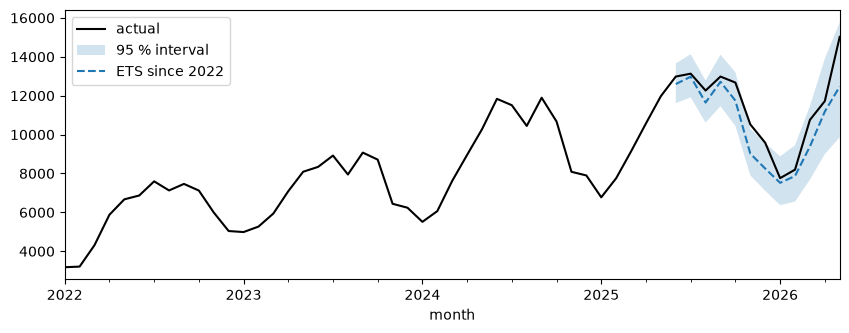

In [8]:
ets = fit_ets(train)
frame = np.exp(ets.get_prediction(start=test.index[0], end=test.index[-1]).summary_frame(alpha=0.05))
ax = y["2022":].plot(figsize=(10, 3.5), color="black", label="actual")
ax.fill_between(frame.index, frame["pi_lower"], frame["pi_upper"], alpha=0.2, label="95 % interval")
frame["mean"].plot(ax=ax, ls="--", label="ETS since 2022")
ax.legend(loc="upper left")
inside = ((test >= frame["pi_lower"]) & (test <= frame["pi_upper"])).sum()
print(f"ETS MAE {mae(test, frame['mean']):.0f}, MASE {mase(test, frame['mean'], train):.2f}, {inside} of {H} months inside the interval")

## 2.2 The airline model with the pandemic marked as missing

The state-space form of ARIMA skips missing months. We mark March 2020 to December 2021 as missing and keep the years before and after.

In [9]:
def fit_airline(y_tr):
    log_gap = np.log(y_tr).where(~covid[y_tr.index])
    return SARIMAX(log_gap, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)


fc = fit_airline(train).get_forecast(H)
air = np.exp(fc.predicted_mean)
ci = np.exp(fc.conf_int(alpha=0.05))
inside = ((test >= ci.iloc[:, 0]) & (test <= ci.iloc[:, 1])).sum()
print(f"airline MAE {mae(test, air):.0f}, MASE {mase(test, air, train):.2f}, {inside} of {H} months inside the interval")

airline MAE 450, MASE 0.27, 12 of 12 months inside the interval


**Exercises.** How much history ETS needs and how the airline model treats the pandemic months are exercises 1.6 and 1.7 in [session-12-exercises.ipynb](session-12-exercises.ipynb).

# Part 3: lag features, backtest and recommendation

## 3.1 A lag-feature model (direct, 12 months ahead)

Target: the yearly growth on the log scale (log y_t − log y_{t−12}), so that a tree can forecast values above the training range. Features: lag 12, lag 24 and the month, all known twelve months ahead. Rows touched by the pandemic (target, lag 12 or lag 24 between March 2020 and December 2021) are dropped.

In [11]:
table = pd.DataFrame({"target": log_y - log_y.shift(12), "lag12": log_y.shift(12),
                      "lag24": log_y.shift(24), "month": y.index.month})
touched = covid | covid.shift(12, fill_value=False) | covid.shift(24, fill_value=False)
table = table[~touched].dropna()


def fit_lag_model(y_tr):
    rows = table.loc[:y_tr.index[-1]]
    return HistGradientBoostingRegressor(min_samples_leaf=5, random_state=0).fit(
        rows.drop(columns="target"), rows["target"])


def predict_lag_model(model, index):
    return np.exp(table.loc[index, "lag12"] + model.predict(table.loc[index].drop(columns="target")))


lag_fc = predict_lag_model(fit_lag_model(train), test.index)
print(len(table.loc[:"2025-05"]), "training rows;", f"lag model MAE {mae(test, lag_fc):.0f}, MASE {mase(test, lag_fc, train):.2f}")

43 training rows; lag model MAE 1011, MASE 0.61


## 3.2 Rolling-origin backtest

Six folds: the origin moves forward three months at a time, from March 2024 to June 2025; each test period has twelve months. The last fold is the hold-out year.

In [12]:
rows = []
for origin in pd.date_range("2024-03-01", "2025-06-01", freq="3MS"):
    test_index = pd.date_range(origin, periods=12, freq="MS")
    y_tr, y_te = y[:origin - pd.offsets.MonthBegin()], y[test_index]
    fcs = baselines(y_tr, test_index)
    pred = np.exp(fit_ets(y_tr).get_prediction(start=test_index[0], end=test_index[-1]).summary_frame(alpha=0.05))
    fcs["ETS"] = pred["mean"]
    a = fit_airline(y_tr).get_forecast(12)
    a_ci = np.exp(a.conf_int(alpha=0.05))
    fcs["airline"] = np.exp(a.predicted_mean)
    fcs["lag model"] = predict_lag_model(fit_lag_model(y_tr), test_index)
    cover = {"ETS": ((y_te >= pred["pi_lower"]) & (y_te <= pred["pi_upper"])).mean(),
             "airline": ((y_te.to_numpy() >= a_ci.iloc[:, 0].to_numpy()) & (y_te.to_numpy() <= a_ci.iloc[:, 1].to_numpy())).mean()}
    for name, fc in fcs.items():
        rows.append({"test from": origin.strftime("%Y-%m"), "model": name, "MAE": mae(y_te, fc),
                     "MASE": mase(y_te, fc, y_tr), "coverage": cover.get(name, np.nan)})
backtest = pd.DataFrame(rows)
backtest.pivot(index="test from", columns="model", values="MASE").round(2)

model,ETS,airline,lag model,moving average (3),naive,seasonal naive,seasonal naive x growth
test from,,,,,,,
2024-03,1.01,0.39,0.48,2.77,2.67,1.65,0.57
2024-06,0.38,0.28,0.39,1.30,1.12,1.47,0.41
2024-09,0.21,0.29,0.60,1.24,1.19,1.06,0.36
2024-12,0.57,0.21,0.67,1.22,1.75,0.97,0.53
2025-03,0.39,0.44,0.80,2.11,1.94,0.90,0.74
2025-06,0.51,0.27,0.61,1.17,1.03,0.96,0.63


In [13]:
summary = backtest.groupby("model").agg(MAE=("MAE", "mean"), MASE=("MASE", "mean"),
                                        MASE_worst=("MASE", "max"), coverage=("coverage", "mean"))
summary["folds best"] = (backtest.loc[backtest.groupby("test from")["MASE"].idxmin(), "model"]
                         .value_counts().reindex(summary.index).fillna(0).astype(int))
summary.sort_values("MASE").round(2)

,MAE,MASE,MASE_worst,coverage,folds best
model,,,,,
airline,482.74,0.31,0.44,1.00,4
ETS,768.50,0.51,1.01,0.83,2
seasonal naive x growth,836.94,0.54,0.74,NaN,0
lag model,933.56,0.59,0.80,NaN,0
seasonal naive,1762.78,1.17,1.65,NaN,0
naive,2460.62,1.62,2.67,NaN,0
moving average (3),2472.75,1.63,2.77,NaN,0


## 3.3 Does the Berlin weather add anything?

Does the weather explain how busy the Airbnb market is? `case-study/prepare_airbnb.py` downloaded the daily Berlin weather from the Open-Meteo API and stored it as `weather_daily.parquet`. The *season* of the weather is already in every model (July is warm and busy every year). The question is whether the *deviations* help: does a warmer or drier month than usual bring more stays?

Be honest about what is known at the forecast origin. Weather forecasts reach about two weeks; for a month twelve months ahead the only usable value is the **climate**, the mean of that month in the training years. We run two versions:

- **actual**: the weather that really happened in the test months, an upper bound that no real forecast can reach;
- **climate**: the monthly mean of the training years, what a forecaster could actually use.

The lag model gets the change of temperature and rain against the same month a year earlier (its target is the growth against that month); the airline model gets the deviation from the usual month as exogenous variables (`exog`).

67 months outside the pandemic


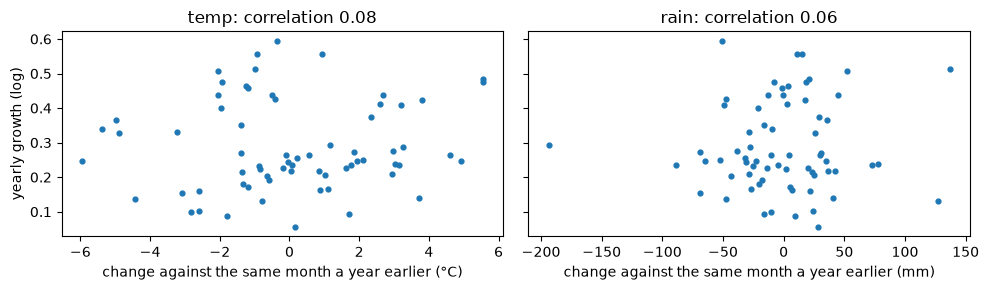

In [14]:
daily = pd.read_parquet(DATA / "weather_daily.parquet").set_index("date")
wx = daily.resample("MS").agg({"temperature_2m_mean": "mean", "precipitation_sum": "sum"}).loc[y.index]
wx.columns = ["temp", "rain"]                                     # °C (monthly mean), mm (monthly total)
pairs = pd.concat([(log_y - log_y.shift(12)).rename("growth"), wx - wx.shift(12)], axis=1)[~touched].dropna()
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, col, unit in zip(axes, ["temp", "rain"], ["°C", "mm"]):
    ax.scatter(pairs[col], pairs["growth"], s=12)
    ax.set_xlabel(f"change against the same month a year earlier ({unit})")
    ax.set_title(f"{col}: correlation {pairs.corr().loc['growth', col]:.2f}")
axes[0].set_ylabel("yearly growth (log)")
plt.tight_layout()
print(len(pairs), "months outside the pandemic")

In [15]:
def weather_change(y_tr, known):
    """Weather minus the same month a year earlier; after the origin the observed or the climate values."""
    w = wx.copy()
    later = w.index > y_tr.index[-1]
    if known == "climate":
        past = wx[:y_tr.index[-1]]
        w.loc[later] = past.groupby(past.index.month).mean().loc[w.index[later].month].to_numpy()
    return (w - wx.shift(12)).add_prefix("change_")


def lag_model_weather(y_tr, index, known):
    t = table.join(weather_change(y_tr, known))
    rows = t.loc[:y_tr.index[-1]]
    model = HistGradientBoostingRegressor(min_samples_leaf=5, random_state=0).fit(
        rows.drop(columns="target"), rows["target"])
    return np.exp(t.loc[index, "lag12"] + model.predict(t.loc[index].drop(columns="target")))


def airline_weather(y_tr, index, known):
    past = wx[:y_tr.index[-1]]
    anomaly = wx - past.groupby(past.index.month).mean().loc[wx.index.month].to_numpy()   # vs the usual month
    future = anomaly.loc[index] if known == "actual" else 0 * anomaly.loc[index]
    log_gap = np.log(y_tr).where(~covid[y_tr.index])
    model = SARIMAX(log_gap, exog=anomaly.loc[y_tr.index], order=(0, 1, 1),
                    seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    return np.exp(model.forecast(len(index), exog=future))


rows = []
for origin in pd.date_range("2024-03-01", "2025-06-01", freq="3MS"):     # the same six folds as in 3.2
    test_index = pd.date_range(origin, periods=12, freq="MS")
    y_tr, y_te = y[:origin - pd.offsets.MonthBegin()], y[test_index]
    for known in ("actual", "climate"):
        rows.append({"test from": origin.strftime("%Y-%m"), "model": f"airline + weather ({known})",
                     "MASE": mase(y_te, airline_weather(y_tr, test_index, known), y_tr)})
        rows.append({"test from": origin.strftime("%Y-%m"), "model": f"lag model + weather ({known})",
                     "MASE": mase(y_te, lag_model_weather(y_tr, test_index, known), y_tr)})
weather_bt = pd.concat([backtest.loc[backtest["model"].isin(["airline", "lag model"]), ["test from", "model", "MASE"]],
                        pd.DataFrame(rows)])
print(weather_bt.pivot(index="test from", columns="model", values="MASE").round(2).to_string())
weather_bt.groupby("model")["MASE"].agg(["mean", "max"]).round(2)

model      airline  airline + weather (actual)  airline + weather (climate)  lag model  lag model + weather (actual)  lag model + weather (climate)
test from                                                                                                                                          
2024-03       0.39                        0.43                         0.45       0.48                          0.49                           0.49
2024-06       0.28                        0.29                         0.29       0.39                          0.42                           0.42
2024-09       0.29                        0.25                         0.25       0.60                          0.62                           0.64
2024-12       0.21                        0.20                         0.21       0.67                          0.75                           0.76
2025-03       0.44                        0.69                         0.69       0.80                          

,mean,max
model,,
airline,0.31,0.44
airline + weather (actual),0.36,0.69
airline + weather (climate),0.36,0.69
lag model,0.59,0.80
lag model + weather (actual),0.63,0.85
lag model + weather (climate),0.64,0.89


**Questions.** (a) Does the weather improve either model, and does it matter whether the observed or the climate values are used? What does it mean if the two versions are almost equal? (b) Why would a version that uses the observed weather of the test months be misleading if it *had* won? (c) Give two reasons why monthly weather hardly moves Berlin's Airbnb demand (think of when stays are booked and why people visit Berlin). (d) Your recommendation should say that the weather was tested. In one sentence: what would you tell the tourism office?

*Reference result (lecture of block 2):* the correlations are below 0.1, and both models get slightly worse with weather (airline mean MASE 0.31 → 0.36, lag model 0.59 → 0.63–0.64), with almost no difference between observed weather and climate.

## 3.4 Recommendation

Write your recommendation for a reader who plans with the forecast, for example the tourism office or a cleaning company (4–6 sentences): which model, its forecast for the next twelve months with the 95 % interval, how accurate it was in the backtest compared with the best simple rule, whether the weather helped, and what could make the forecast wrong (reviews as a proxy for stays, listings missing from the snapshot, the unusually high May 2026, the EU registration rules that apply since 20 May 2026).

The cell below refits the airline model on all data up to May 2026 and forecasts June 2026 to May 2027.

expected total June 2026 to May 2027: 168301 (last 12 months: 137595)


,mean,pi_lower,pi_upper
2026-06-01,15813.0,13854.0,18048.0
2026-07-01,16130.0,13640.0,19074.0
2026-08-01,14876.0,12219.0,18111.0
2026-09-01,16303.0,13056.0,20358.0
2026-10-01,15378.0,12038.0,19643.0
2026-11-01,12182.0,9340.0,15887.0
2026-12-01,11307.0,8504.0,15033.0
2027-01-01,9771.0,7218.0,13226.0
2027-02-01,10511.0,7634.0,14472.0
2027-03-01,13107.0,9367.0,18340.0


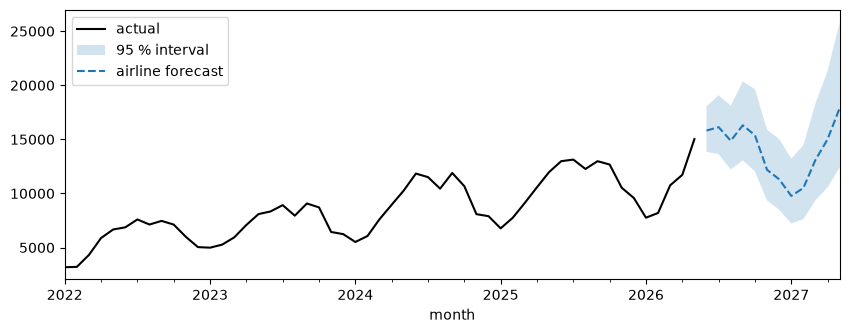

In [16]:
final = fit_airline(y)
fc = final.get_forecast(12)
outlook = pd.DataFrame({"mean": np.exp(fc.predicted_mean)}).join(np.exp(fc.conf_int(alpha=0.05)))
outlook.columns = ["mean", "pi_lower", "pi_upper"]
ax = y["2022":].plot(figsize=(10, 3.5), color="black", label="actual")
ax.fill_between(outlook.index, outlook["pi_lower"], outlook["pi_upper"], alpha=0.2, label="95 % interval")
outlook["mean"].plot(ax=ax, ls="--", label="airline forecast")
ax.legend(loc="upper left")
print(f"expected total June 2026 to May 2027: {outlook['mean'].sum():.0f} (last 12 months: {y['2025-06':].sum()})")
outlook.round(0)

*Your recommendation:* ...

# Part 4 (optional): many smaller series, one per district

A district office plans for its own area. We join each listing's district and repeat the hold-out comparison for the twelve districts: does the ranking of the models hold for smaller, noisier series?

In [17]:
listings = pd.read_parquet(DATA / "listings.parquet", columns=["id", "district"])
by_district = reviews.merge(listings, left_on="listing_id", right_on="id")
months = pd.date_range("2016-01-01", "2026-05-01", freq="MS")
rows = []
for district, part in by_district.groupby("district"):
    s = part.groupby("month")["n_reviews"].sum().reindex(months, fill_value=0).astype(float)   # keep empty months
    s.index.freq = "MS"
    s_tr, s_te = s[:"2025-05"], s["2025-06":]
    b = baselines(s_tr, s_te.index)
    ets_d = np.exp(ETSModel(np.log1p(s_tr["2022":]), error="add", trend="add", damped_trend=True,
                            seasonal="add", seasonal_periods=12).fit(disp=False).forecast(12)) - 1
    log_gap = np.log1p(s_tr).where(~covid[s_tr.index])
    air_d = np.exp(SARIMAX(log_gap, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(12)) - 1
    rows.append({"district": district, "mean per month": round(s_te.mean()),
                 "MASE seasonal naive x growth": mase(s_te, b["seasonal naive x growth"], s_tr),
                 "MASE ETS": mase(s_te, ets_d, s_tr), "MASE airline": mase(s_te, air_d, s_tr)})
pd.DataFrame(rows).sort_values("mean per month", ascending=False).round(2)

,district,mean per month,MASE seasonal naive x growth,MASE ETS,MASE airline
4,Mitte,2867,0.66,0.53,0.32
1,Friedrichshain-Kreuzberg,2687,0.65,0.67,0.40
6,Pankow,1899,0.56,0.64,0.52
0,Charlottenburg-Wilm.,1140,1.59,0.69,0.40
5,Neukölln,733,0.82,0.66,0.54
10,Tempelhof - Schöneberg,721,1.79,0.60,0.60
11,Treptow - Köpenick,331,1.09,1.13,1.42
2,Lichtenberg,320,1.54,0.47,0.76
9,Steglitz - Zehlendorf,228,0.75,0.98,0.73
7,Reinickendorf,141,0.78,0.67,0.94


## Exercises

The exercises on this case study are in [session-12-exercises.ipynb](session-12-exercises.ipynb), part 1 and part 2.